In [4]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/Crop_recommendation.csv")
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [6]:
df.tail()

,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


In [7]:
df.shape

(2200, 8)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


In [9]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [10]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['label'].unique()

<ArrowStringArray>
[       'rice',       'maize',    'chickpea', 'kidneybeans',  'pigeonpeas',
   'mothbeans',    'mungbean',   'blackgram',      'lentil', 'pomegranate',
      'banana',       'mango',      'grapes',  'watermelon',   'muskmelon',
       'apple',      'orange',      'papaya',     'coconut',      'cotton',
        'jute',      'coffee']
Length: 22, dtype: str

In [13]:
df['label'].nunique()

22

In [14]:
df['label'].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

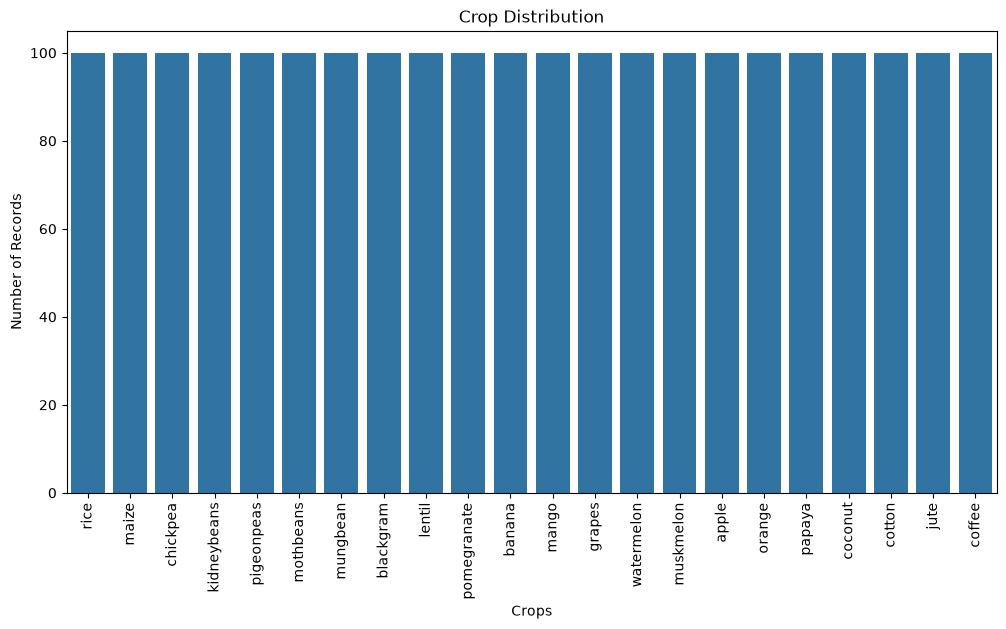

In [15]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x='label')

plt.xticks(rotation=90)
plt.title("Crop Distribution")
plt.xlabel("Crops")
plt.ylabel("Number of Records")

plt.show()

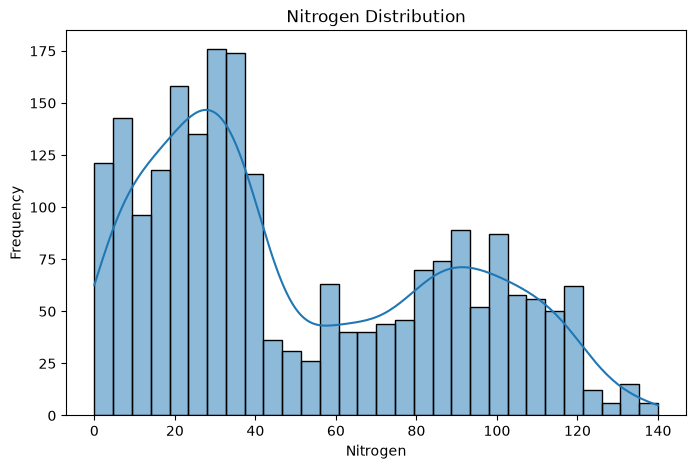

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(df['N'], bins=30, kde=True)

plt.title("Nitrogen Distribution")
plt.xlabel("Nitrogen")
plt.ylabel("Frequency")

plt.show()

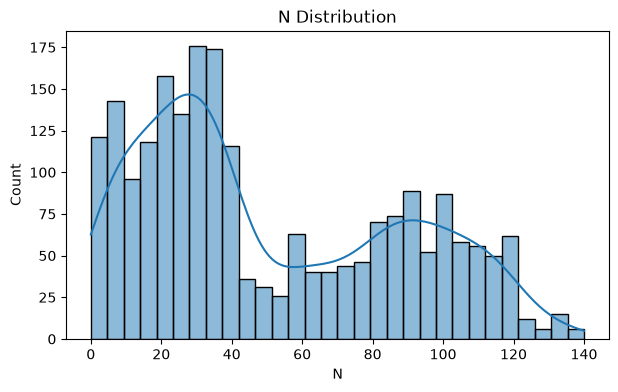

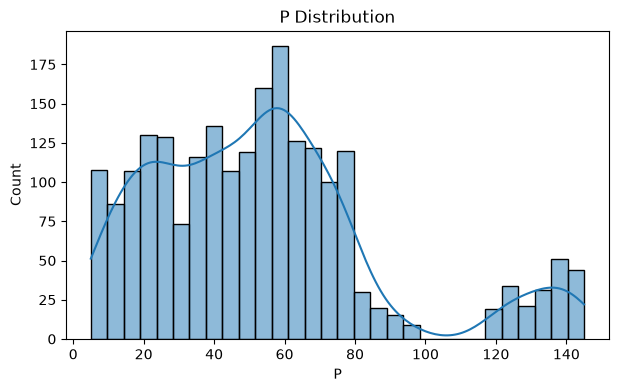

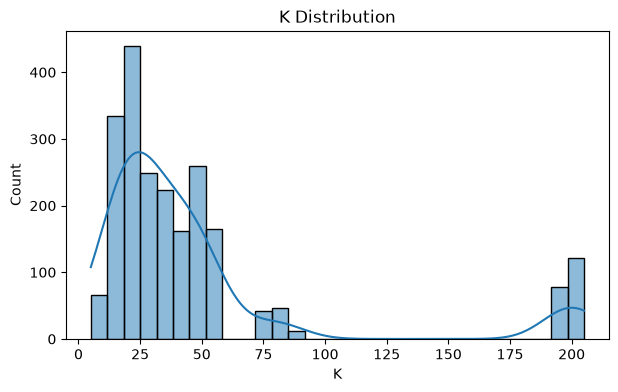

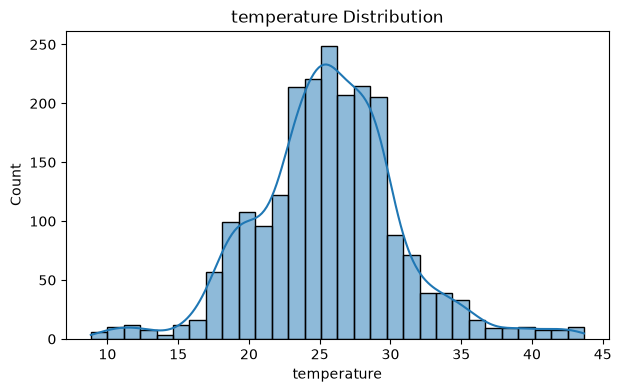

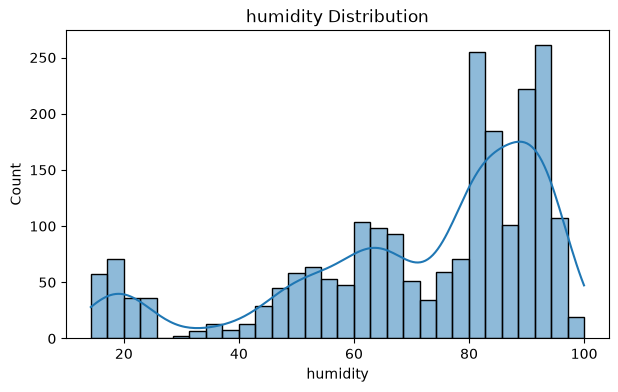

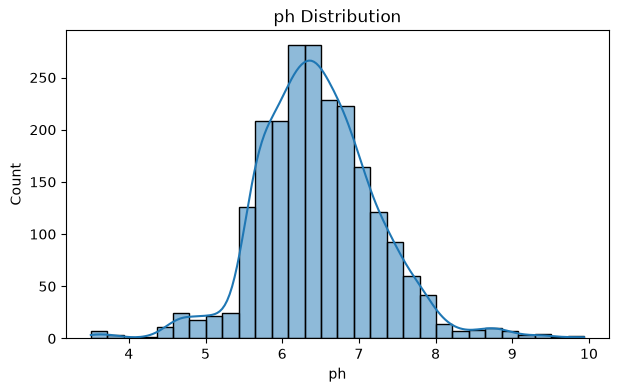

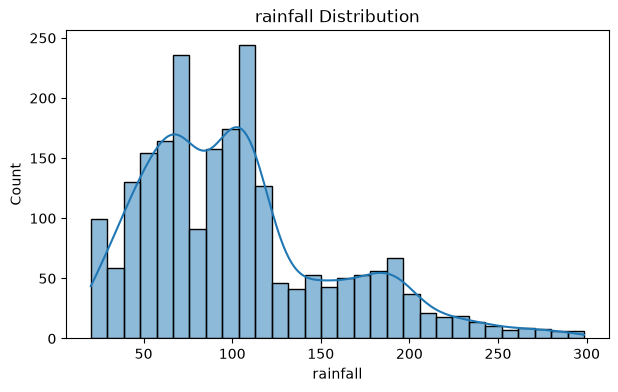

In [17]:
features = [
    'N', 'P', 'K',
    'temperature', 'humidity',
    'ph', 'rainfall'
]

for feature in features:

    plt.figure(figsize=(7, 4))

    sns.histplot(df[feature], bins=30, kde=True)

    plt.title(f"{feature} Distribution")

    plt.show()

In [18]:
correlation = df[features].corr()

print(correlation)

                    N         P         K  temperature  humidity        ph  \
N            1.000000 -0.231460 -0.140512     0.026504  0.190688  0.096683   
P           -0.231460  1.000000  0.736232    -0.127541 -0.118734 -0.138019   
K           -0.140512  0.736232  1.000000    -0.160387  0.190859 -0.169503   
temperature  0.026504 -0.127541 -0.160387     1.000000  0.205320 -0.017795   
humidity     0.190688 -0.118734  0.190859     0.205320  1.000000 -0.008483   
ph           0.096683 -0.138019 -0.169503    -0.017795 -0.008483  1.000000   
rainfall     0.059020 -0.063839 -0.053461    -0.030084  0.094423 -0.109069   

             rainfall  
N            0.059020  
P           -0.063839  
K           -0.053461  
temperature -0.030084  
humidity     0.094423  
ph          -0.109069  
rainfall     1.000000  


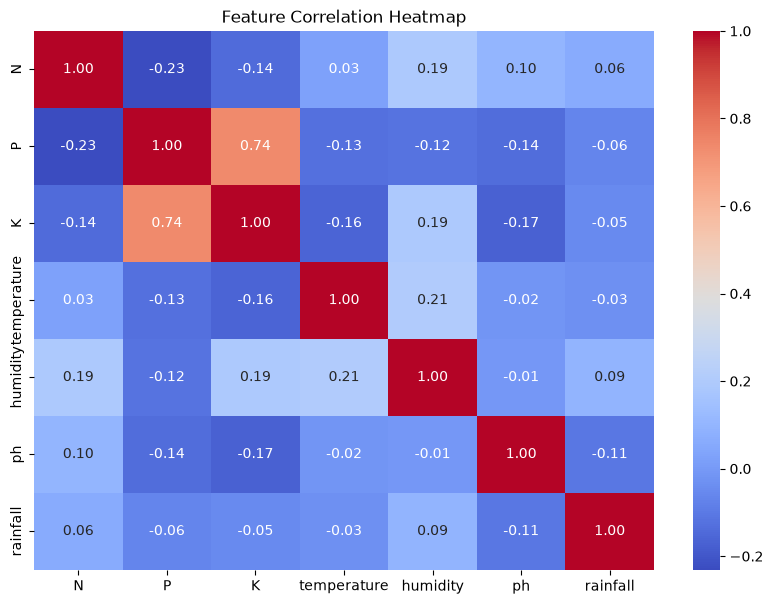

In [19]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")

plt.show()

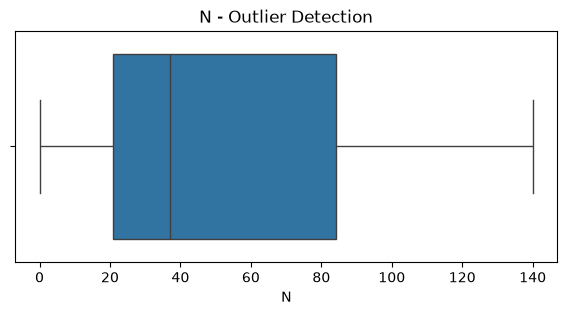

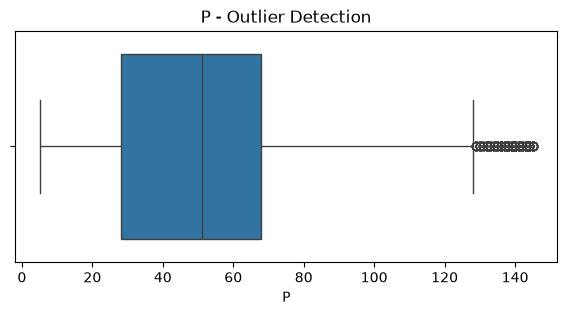

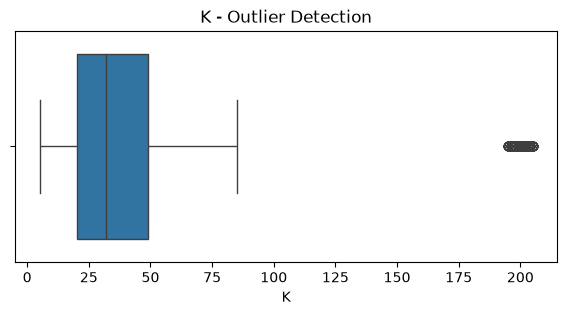

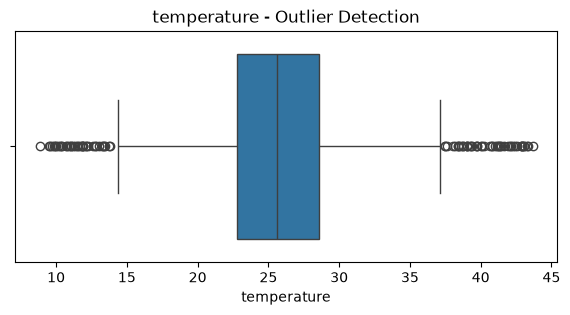

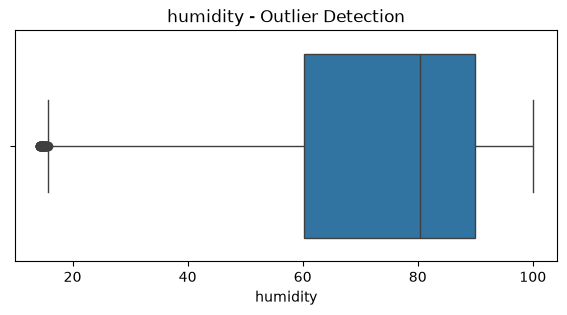

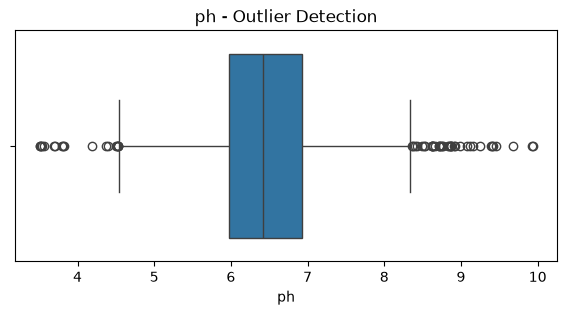

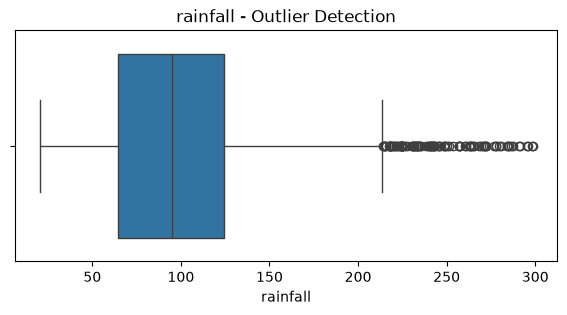

In [20]:
for feature in features:

    plt.figure(figsize=(7, 3))

    sns.boxplot(x=df[feature])

    plt.title(f"{feature} - Outlier Detection")

    plt.show()

In [21]:
df['label'].nunique()

22

In [22]:
df['label'].unique()

<ArrowStringArray>
[       'rice',       'maize',    'chickpea', 'kidneybeans',  'pigeonpeas',
   'mothbeans',    'mungbean',   'blackgram',      'lentil', 'pomegranate',
      'banana',       'mango',      'grapes',  'watermelon',   'muskmelon',
       'apple',      'orange',      'papaya',     'coconut',      'cotton',
        'jute',      'coffee']
Length: 22, dtype: str

In [23]:
# Independent variables / Features
X = df.drop('label', axis=1)

# Dependent variable / Target
y = df['label']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2200, 7)
Target shape: (2200,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1760, 7)
X_test: (440, 7)
y_train: (1760,)
y_test: (440,)


In [26]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Predicted:", y_pred[:10])

print("Actual:", y_test.iloc[:10].values)

Predicted: ['orange' 'banana' 'cotton' 'maize' 'orange' 'chickpea' 'rice' 'blackgram'
 'banana' 'orange']
Actual: <ArrowStringArray>
[   'orange',    'banana',    'cotton',     'maize',    'orange',  'chickpea',
      'rice', 'blackgram',    'banana',    'orange']
Length: 10, dtype: str


In [27]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 99.54545454545455 %


In [28]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

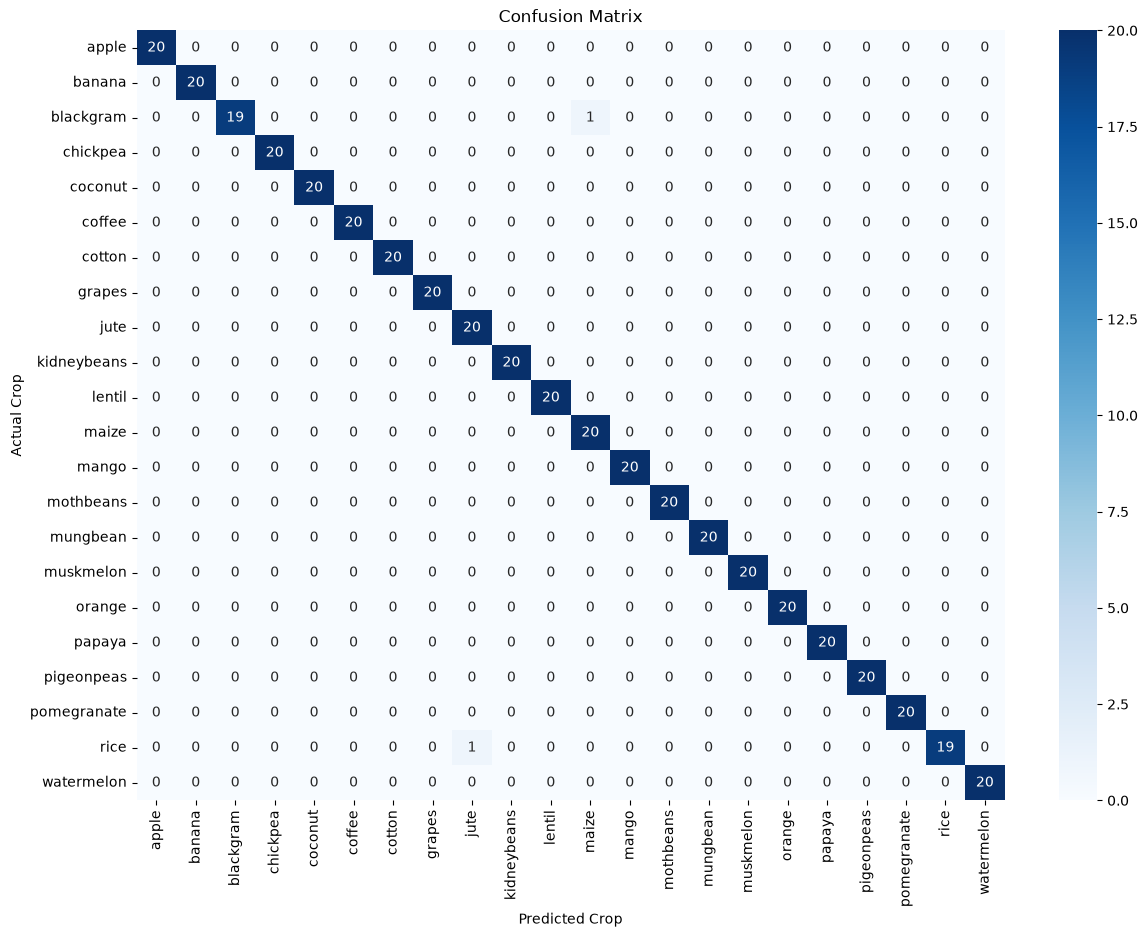

In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.title("Confusion Matrix")

plt.show()

In [30]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

       Feature  Importance
6     rainfall    0.230184
4     humidity    0.224227
2            K    0.175393
1            P    0.150850
0            N    0.096363
3  temperature    0.072375
5           ph    0.050608


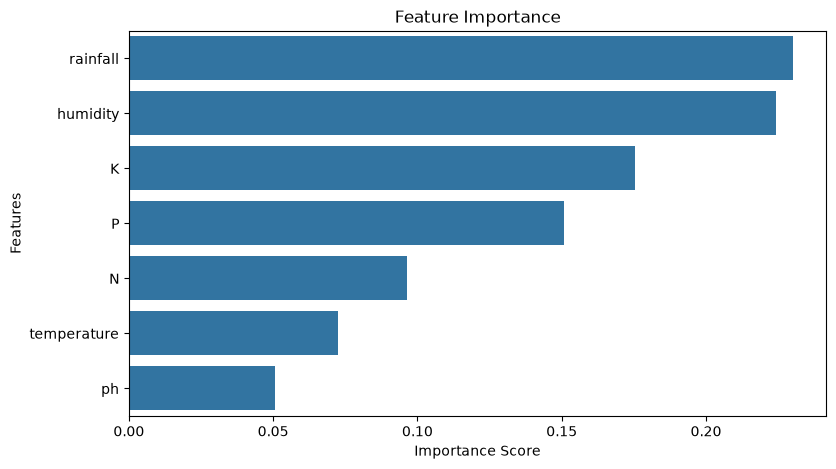

In [31]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.show()

In [32]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)

print("Best CV Accuracy:", grid_search.best_score_ * 100, "%")

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Accuracy: 99.6022727272727 %


In [33]:
from sklearn.metrics import accuracy_score

old_accuracy = accuracy_score(
    y_test,
    model.predict(X_test)
)

new_accuracy = accuracy_score(
    y_test,
    best_model.predict(X_test)
)

print("Old Model:", old_accuracy * 100, "%")
print("Improved Model:", new_accuracy * 100, "%")

Old Model: 99.54545454545455 %
Improved Model: 99.54545454545455 %


In [37]:
# Now saving the model
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    {
        "model": best_model,
        "features": list(X.columns)
    },
    "../models/crop_model.pkl"
)

['../models/crop_model.pkl']

In [36]:
saved_data = joblib.load("../models/crop_model.pkl")

loaded_model = saved_data["model"]
feature_names = saved_data["features"]

In [ ]:
sample = X_test.iloc[:10]

predictions = loaded_model.predict(sample)

for index, prediction in enumerate(predictions):

    print("Predicted Crop:", prediction)
    print("Actual Crop:", y_test.iloc[index])
    print("------------------------")

Predicted Crop: orange
Actual Crop: orange
------------------------
Predicted Crop: banana
Actual Crop: banana
------------------------
Predicted Crop: cotton
Actual Crop: cotton
------------------------
Predicted Crop: maize
Actual Crop: maize
------------------------
Predicted Crop: orange
Actual Crop: orange
------------------------
Predicted Crop: chickpea
Actual Crop: chickpea
------------------------
Predicted Crop: rice
Actual Crop: rice
------------------------
Predicted Crop: blackgram
Actual Crop: blackgram
------------------------
Predicted Crop: banana
Actual Crop: banana
------------------------
Predicted Crop: orange
Actual Crop: orange
------------------------
